# code_080 · Gaussian processes and scalable approximations

**Book:** section 16.4. A self-contained probabilistic response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_16_GUIDE.md), [run evidence](../CHAPTER_16_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_080).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1680;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1680


<a id="conditioning"></a>
## A fixed covariance defines what spatial interpolation assumes

A one-dimensional temperature transect has sixteen sensor locations in[.2,3.5]m. Generate observations from20+1.7*sin(1.2*x) Celsius plus Normal noise SD.15C. Assume a GP mean20C, RBF prior variance4C², length.8m and known independent noise variance.15²C². Hyperparameters are fixed, not fitted or selected on assessment. Manual Cholesky conditioning is checked against sklearn optimizerNone, normalize_yFalse on centered observations. Query pointwise latent95% intervals exclude observation noise; future-reading intervals add it. Independent forty-reading cohorts inside sensor support and at4.5–6m audit squared error and interval coverage under the declared generator, not a coverage theorem or external field validation.


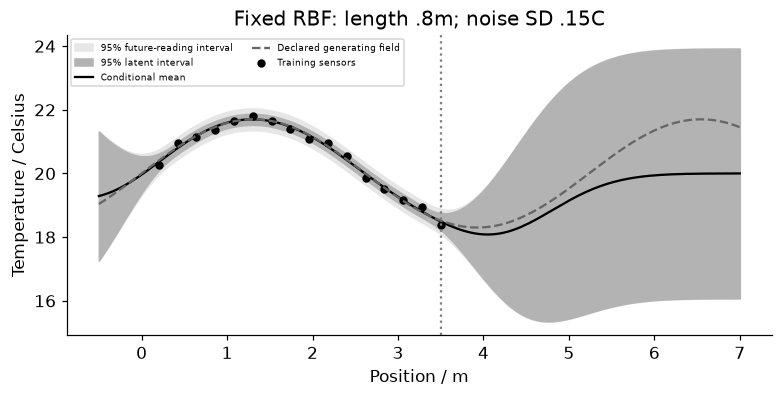

In [2]:
from scipy.linalg import solve_triangular,cho_solve
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel,RBF
noise=.15;variance=4.;length=.8;mean0=20.;x=np.linspace(.2,3.5,16);truth=lambda z:20+1.7*np.sin(1.2*z);y=truth(x)+rng.normal(0,noise,len(x))
def kernel(a,b):return variance*np.exp(-.5*((np.asarray(a)[:,None]-np.asarray(b)[None,:])/length)**2)
C=kernel(x,x)+noise**2*np.eye(len(x));chol=np.linalg.cholesky(C);alpha=cho_solve((chol,True),y-mean0)
def posterior(q):
 cross=kernel(x,q);v=solve_triangular(chol,cross,lower=True);return mean0+cross.T@alpha,np.maximum(0,variance-np.sum(v*v,axis=0))
grid=np.linspace(-.5,7,180);mu,var=posterior(grid);sk=GaussianProcessRegressor(kernel=ConstantKernel(4,constant_value_bounds='fixed')*RBF(.8,length_scale_bounds='fixed'),alpha=noise**2,optimizer=None,normalize_y=False).fit(x[:,None],y-20);skmu,skstd=sk.predict(grid[:,None],return_std=True);np.testing.assert_allclose(mu,skmu+20,atol=1e-10);np.testing.assert_allclose(var,skstd**2,atol=1e-10);assert np.all(var>=0)
rows=[]
for name,bounds in [('inside',[.2,3.5]),('far',[4.5,6])]:
 q=rng.uniform(*bounds,40);actual=truth(q)+rng.normal(0,noise,len(q));pred,v=posterior(q);std=np.sqrt(v+noise**2);rows.append({'cohort':name,'readings':40,'squared_error_mean_C2':float(np.mean((actual-pred)**2)),'pointwise_future_interval_coverage':float(np.mean(np.abs(actual-pred)<=1.96*std)),'mean_latent_variance_C2':float(v.mean())})
RESULTS['GP']={'sensors':16,'mean_C':20.,'RBF_variance_C2':4.,'length_m':.8,'noise_SD_C':.15,'hyperparameter_selection':False,'manual_library_agreement':True,'assessment':rows}
fig,ax=plt.subplots(figsize=(7,3.5));ax.fill_between(grid,mu-1.96*np.sqrt(var+noise**2),mu+1.96*np.sqrt(var+noise**2),color='.9',label='95% future-reading interval');ax.fill_between(grid,mu-1.96*np.sqrt(var),mu+1.96*np.sqrt(var),color='.7',label='95% latent interval');ax.plot(grid,mu,color='black',label='Conditional mean');ax.plot(grid,truth(grid),'--',color='.4',label='Declared generating field');ax.scatter(x,y,s=20,color='black',label='Training sensors');ax.axvline(3.5,color='.5',ls=':');ax.set(xlabel='Position / m',ylabel='Temperature / Celsius',title='Fixed RBF: length .8m; noise SD .15C');ax.legend(fontsize=6,ncol=2);plt.show()


<a id="approximation"></a>
## A naive low-rank prior can erase uncertainty away from its basis

Use five fixed inducing locations inside the sensor range and features Phi(x)=K(x,Z)*K(Z,Z)^(-1/2), implemented through a Cholesky factor. A Gaussian linear model with unit weight covariance replaces the entire GP prior covariance by Phi*Phi.T. Its rank-five prior variance vanishes far from Z; the conditional weight variance cannot restore the omitted residual K-Q. This is an intentionally incomplete low-rank-prior approximation, not a claim that proper inducing-variable or variational GPs behave this way. Correct sparse methods require their own residual/conditional covariance and inference specification. Report the failure mechanism instead of advertising low uncertainty as confidence.


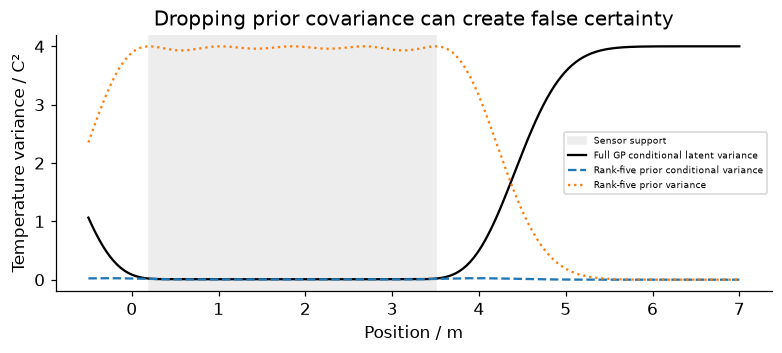

In [3]:
Z=np.linspace(.2,3.5,5);Lz=np.linalg.cholesky(kernel(Z,Z))
def features(q):return solve_triangular(Lz,kernel(Z,q),lower=True).T
Phi=features(x);precision=np.eye(5)+Phi.T@Phi/noise**2;S=np.linalg.solve(precision,np.eye(5));w=S@Phi.T@(y-mean0)/noise**2;F=features(grid);low_mu=mean0+F@w;low_var=np.sum((F@S)*F,axis=1);prior_low=np.sum(F*F,axis=1);far_mean,far_var=posterior(np.array([10.]));far_features=features(np.array([10.]));far_low=float((far_features@S@far_features.T)[0,0]);assert far_var[0]>3.99 and far_low<1e-10;assert np.all(low_var>=0) and np.all(prior_low<=variance+1e-10)
RESULTS['low_rank_prior']={'rank':5,'inducing_locations_m':Z.tolist(),'at_10m_full_latent_variance_C2':float(far_var[0]),'at_10m_low_rank_latent_variance_C2':far_low,'omitted_component':'K-Q prior residual; this is not a complete sparse GP method','grid_mean_prediction_difference_C':float(np.mean(np.abs(mu-low_mu)))}
fig,ax=plt.subplots(figsize=(7,3.1));ax.axvspan(.2,3.5,color='.93',label='Sensor support');ax.plot(grid,var,'-',color='black',label='Full GP conditional latent variance');ax.plot(grid,low_var,'--',label='Rank-five prior conditional variance');ax.plot(grid,prior_low,':',label='Rank-five prior variance');ax.set(xlabel='Position / m',ylabel='Temperature variance / C²',title='Dropping prior covariance can create false certainty');ax.legend(fontsize=6);plt.show()


In [4]:
summary={'example_id':'code_080','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['fixed covariance and Gaussian conditioning', 'latent versus observation intervals', 'away-from-support conditional uncertainty', 'low-rank prior approximation and variance loss'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["fixed covariance and Gaussian conditioning", "latent versus observation intervals", "away-from-support conditional uncertainty", "low-rank prior approximation and variance loss"], "elapsed_seconds": 0.224, "example_id": "code_080", "hardware": "Darwin arm64 CPU", "results": {"GP": {"RBF_variance_C2": 4.0, "assessment": [{"cohort": "inside", "mean_latent_variance_C2": 0.008645341201899137, "pointwise_future_interval_coverage": 0.975, "readings": 40, "squared_error_mean_C2": 0.019972833604827996}, {"cohort": "far", "mean_latent_variance_C2": 3.4845973814508917, "pointwise_future_interval_coverage": 1.0, "readings": 40, "squared_error_mean_C2": 0.45652552864528156}], "hyperparameter_selection": false, "length_m": 0.8, "manual_library_agreement": true, "mean_C": 20.0, "noise_SD_C": 0.15, "sensors": 16}, "low_rank_prior": {"at_10m_full_latent_variance_C2": 4.0, "at_10m_low_rank_latent_variance_C2": 2.1105807608149698e-30, "grid_mean_predict